
# **Ex 11: Multilateration - Non-linear least squares**
*This exercise was previously assigned as the second exercise in a previous exam.*

Perform the least-squares adjustment of the planimetric network sketched in the figure.

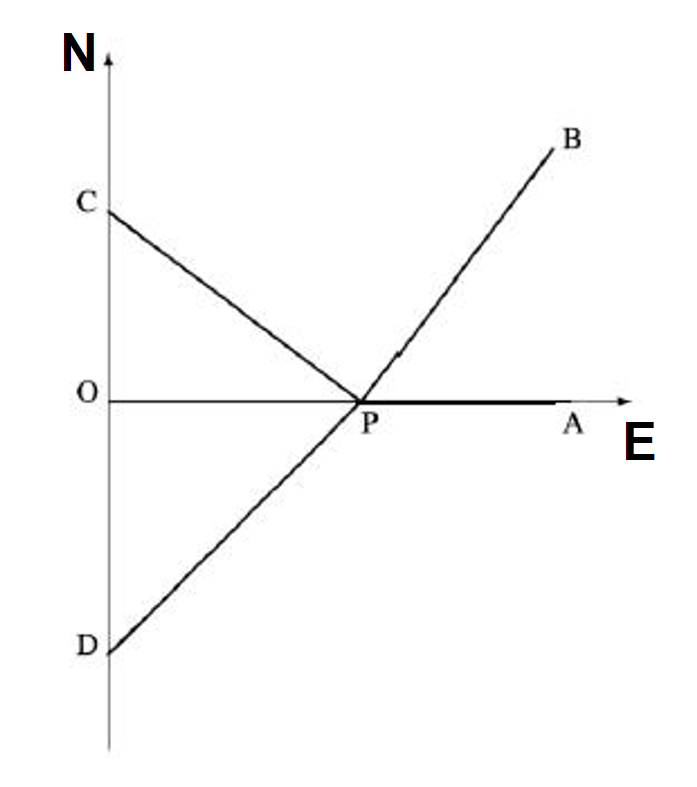



Given the coordinates of the known points O, A, B, C and D, determine the planimetric coordinates of the unknown point P and the covariance matrix of the estimated parameters.

Known Points:

O(E, N) = (  0,   0) m

A(E, N) = (700,   0) m

B(E, N) = (700, 400) m

C(E, N) = (  0, 300) m

D(E, N) = (  0,-400) m



A series of horizontal distance measurements to point P was collected from the five known points using a laser distance meter.

The distance observations are assumed to be uncorrelated and to have equal precision, with a standard deviation of $\sigma_d$ = 30mm.

The observations (in metres) are assumed to be normally distributed and are reported in the following table.





 $d_{OP}$    | $d_{AP}$     |    $d_{BP}$  |	$d_{CP}$    |	$d_{DP}$     |
-------------|--------------|--------------|--------------|--------------|
400.0218072  | 300.0379993  |  499.9974327            |       499.9703278       |       566.7193918       |
|

Implement the iterative Gauss–Newton procedure to solve the nonlinear system of observation equations, estimate the coordinates of P and the covariance matrix of the estimated parameters, and check whether the Overall Model Test (OMT) is passed at the 1% significance level.

Assume the following approximate coordinates for point P:

P(E,N) = (300, 50) m

If the OMT is rejected, investigate whether a potential outlier could be responsible for the rejection. Remove the candidate outlier observation and repeat the estimation process. Then recompute the OMT to assess whether the test result changes.

**Answer the following questions:**

***Q1:*** Was it possible to identify an outlier in the observations? What strategy did you use? Explain your reasoning.

***Q2:*** What do the values along the diagonal of the matrix $Q_{\hat{x}\hat{x}}$ represent? What can we conclude by comparing the values of the diagonal of the covariance matrix of the estimated parameters $Q_{\hat{x}\hat{x}}$? What is the effect of the possible outlier in the calculation of the $Q_{\hat{x}\hat{x}}$ matrix?

***Q3:*** Compute the confidence intervals at the 95% level for the estimated planimetric coodinates of the point P.

**Q4:** Compute the **95% confidence ellipse** for the estimated planimetric coordinates of point P. Report the lengths of its semi-major and semi-minor axes and its orientation. Explain how the covariance matrix of the estimated parameters is used to derive the ellipse.


**Submission EX2: **

You must submit the Colab notebook containing the code that you implemented to solve the exercise, highlighting the following information:

  
  * number of observations ($m$)
  * number of unknown parameters ($n$)
  * equations of observations, i.e. the functional model and the design matrix $A(x)$
  * analytical steps for calculating the Jacobian matrix $J$ (attach photos/screenshots)
  * computed Jacobian Matrix $J$ at the first and the last iteration
  * covariance matrix of observations $Q_{yy}$
  * inverse of covariance matrix of observations $Q{^{-1}}_{yy}$
  * normal matrix $N$
  * inverse of normal matrix $N^{-1}$
  * OMT result with and without outliers
  * the estimated parameters $\hat{x}$ with and without outliers
  * covariance matrix of the estimated parameters $Q_{\hat{x}\hat{x}}$ with and without outliers
  * answers to the questions




**Edit the cell to reply**

From the theoretical point of view, you will need to know how to to compute the derivatives of the distances (www.mathsisfun.com/calculus/derivatives-rules.html) in order to obtain the linearized functional model, i.e.  the linear approximation of the non­‐linear functions within the non-linear functional model, and to find the expression for the Jacobian matrix $J$.

From the informatic point of view, you will need to know how to:

*    use the matrix multiplication operator `@` (https://alysivji.com/python-matrix-multiplication-operator.html, https://www.geeksforgeeks.org/numpy/multiplication-two-matrices-single-line-using-numpy-python/);
*   stack a sequence of input arrays vertically to make a single array (function `numpy.vstack()`: https://www.geeksforgeeks.org/numpy-vstack-in-python/);
*   compute the rank of a matrix (function `numpy.linalg.matrix_rank`: https://codesignal.com/learn/courses/fundamentals-of-vectors-and-matrices-with-numpy/lessons/matrix-rank-with-numpy);
*  invert a matrix (function `np.linalg.inv()`: https://www.geeksforgeeks.org/how-to-inverse-a-matrix-using-numpy/ );
*   transpose a matrix (method `.T` of numpy arrays: https://www.geeksforgeeks.org/transpose-matrix-single-line-python/);
*   create a diagonal matrix from a NumPy array: https://sparkbyexamples.com/python/how-to-get-numpy-diagonal/#:~:text=Numpy%20diag()%20function%20is,1%20for%20the%20below%20diagonal (see Section 5 of the link);
*   use the normal percentiles for the confidence intervals (function `scipy.ppf`): https://pieriantraining.com/working-with-scipy-stats-norm-a-guide/#:~:text=Finding%20Percentiles%20with%20Scipy%20Stats%20Norm, https://www.geo.fu-berlin.de/en/v/soga-py/Basics-of-statistics/Continous-Random-Variables/The-Standard-Normal-Distribution/Determining-the-z-Value/index.html
*   use the $\chi^2$ pdf for computing the test statistic $K$: https://www.geeksforgeeks.org/scipy-stats-chi2-python/;
*   delete an element from a numpy array using the method `np.delete()`: https://www.geeksforgeeks.org/how-to-remove-specific-elements-from-a-numpy-array/;
* implent logical conditions and conditional statements (`if`, `else`) in Python: https://www.w3schools.com/python/python_conditions.asp;
* implement functions using the `def` keyword: https://www.geeksforgeeks.org/python-functions/;
* reshape your 1D numpy arrays to the desired 2D dimensions using the `reshape` method of numpy arrays: https://www.geeksforgeeks.org/convert-a-1d-array-to-a-2d-numpy-array/;
* understand the while loop: https://www.geeksforgeeks.org/python-while-loop/;
* visualize a matrix with plt.imshow: https://scipython.com/book/chapter-7-matplotlib/examples/visualizing-a-matrix-with-imshow/.


Number of observations:  0
y
 0
σd (m) 0
Qyy
 0
Number of unknowns (n):  0
xi
 0


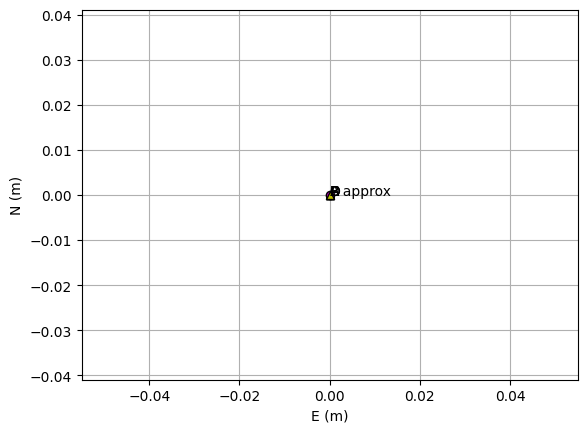

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats.distributions import chi2

# The coordinates of the known points
EO = 0 # replace the 0 with the correct expression      # m
NO = 0 # replace the 0 with the correct expression      # m
O = (EO,NO)  # m
EA = 0 # replace the 0 with the correct expression      # m
NA = 0 # replace the 0 with the correct expression      # m
A = (EA,NA)  # m
EB = 0 # replace the 0 with the correct expression      # m
NB = 0 # replace the 0 with the correct expression      # m
B = (EB,NB)  # m
EC = 0 # replace the 0 with the correct expression      # m
NC = 0 # replace the 0 with the correct expression      # m
C = (EC,NC)  # m
ED = 0 # replace the 0 with the correct expression      # m
ND = 0 # replace the 0 with the correct expression      # m
D = (ED,ND)  # m

# The observed distances
dOP = 0 # replace the 0 with the correct expression	    # m
dAP = 0 # replace the 0 with the correct expression   	# m
dBP = 0 # replace the 0 with the correct expression	    # m
dCP = 0 # replace the 0 with the correct expression	    # m
dDP = 0 # replace the 0 with the correct expression     # m

# Define the observation vector and store it in a variable named y
# Consider that you could be forced to reshape y
y = 0 # replace the 0 with the correct expression
# Compute the number of observations and store it in the variable named m
m = 0 # replace the 0 with the correct expression
#y = y.reshape((m,1))

'''
# Remove the outlier
# Uncomment the following lines to remove the outlier
# Remember that you need also to comment the corresponding row
# in the functions of the design matrix and of the Jacobian
index_outlier = 0 # replace the 0 with the correct expression
y = np.delete(y,index_outlier)
m = len (y)
y = y.reshape((m,1))
'''
print("Number of observations: ", m)
print('y\n',y)
#print('y shape\n',y.shape)

# Define the standard deviation of the measurments (in m) and store it in the variable named sigma_d_m
sigma_d_m = 0 # replace the 0 with the correct expression
print('σd (m)',sigma_d_m)

# Define the covariance matrix of observations and store it in the variable named Qyy
Qyy = 0 # replace the 0 with the correct expression
print('Qyy\n', Qyy)
# print('Qyy shape\n', Qyy.shape)

# Define the number of unknows and store it in the variable named n
n = 0 # replace the 0 with the correct expression
print("Number of unknowns (n): ", n)

# Initial guess for the unknown coordinates of the point P

EP_approx = 0 # replace the 0 with the correct expression # m
NP_approx = 0 # replace the 0 with the correct expression # m
# Consider that you could be forced to reshape xi
xi = 0 # replace the 0 with the correct expression
print('xi\n',xi)
#xi = xi.reshape((n,1))
#print('xi shape\n',xi.shape)

# Plot all the points coordinates
fig, ax = plt.subplots()
ax.axis('equal')
plt.plot(A[0],A[1], 'r^',label='A', markeredgecolor='k')
plt.plot(B[0],B[1], 'b^',label='B', markeredgecolor='k')
plt.plot(C[0],C[1], 'g^',label='C', markeredgecolor='k')
plt.plot(D[0],D[1], 'w^',label='C', markeredgecolor='k')
plt.plot(EP_approx,NP_approx, 'mo',label='P approx', markeredgecolor='k')
plt.plot(O[0],O[1], 'y^',label='O', markeredgecolor='k')
plt.text(A[0],A[1],'A')
plt.text(B[0],B[1],'B')
plt.text(C[0],C[1],'C')
plt.text(D[0],D[1],'D')
plt.text(O[0],O[1],'O')
plt.text(EP_approx,NP_approx,'P approx')
plt.xlabel('E (m)')
plt.ylabel('N (m)')
plt.grid()
plt.grid(which='minor')
plt.show()

**Functional model definition**

Define the functional model for the problem.

To help you, I provide the first non linear function ($a_1(E_P, N_P)$): at the exam this will not happen.

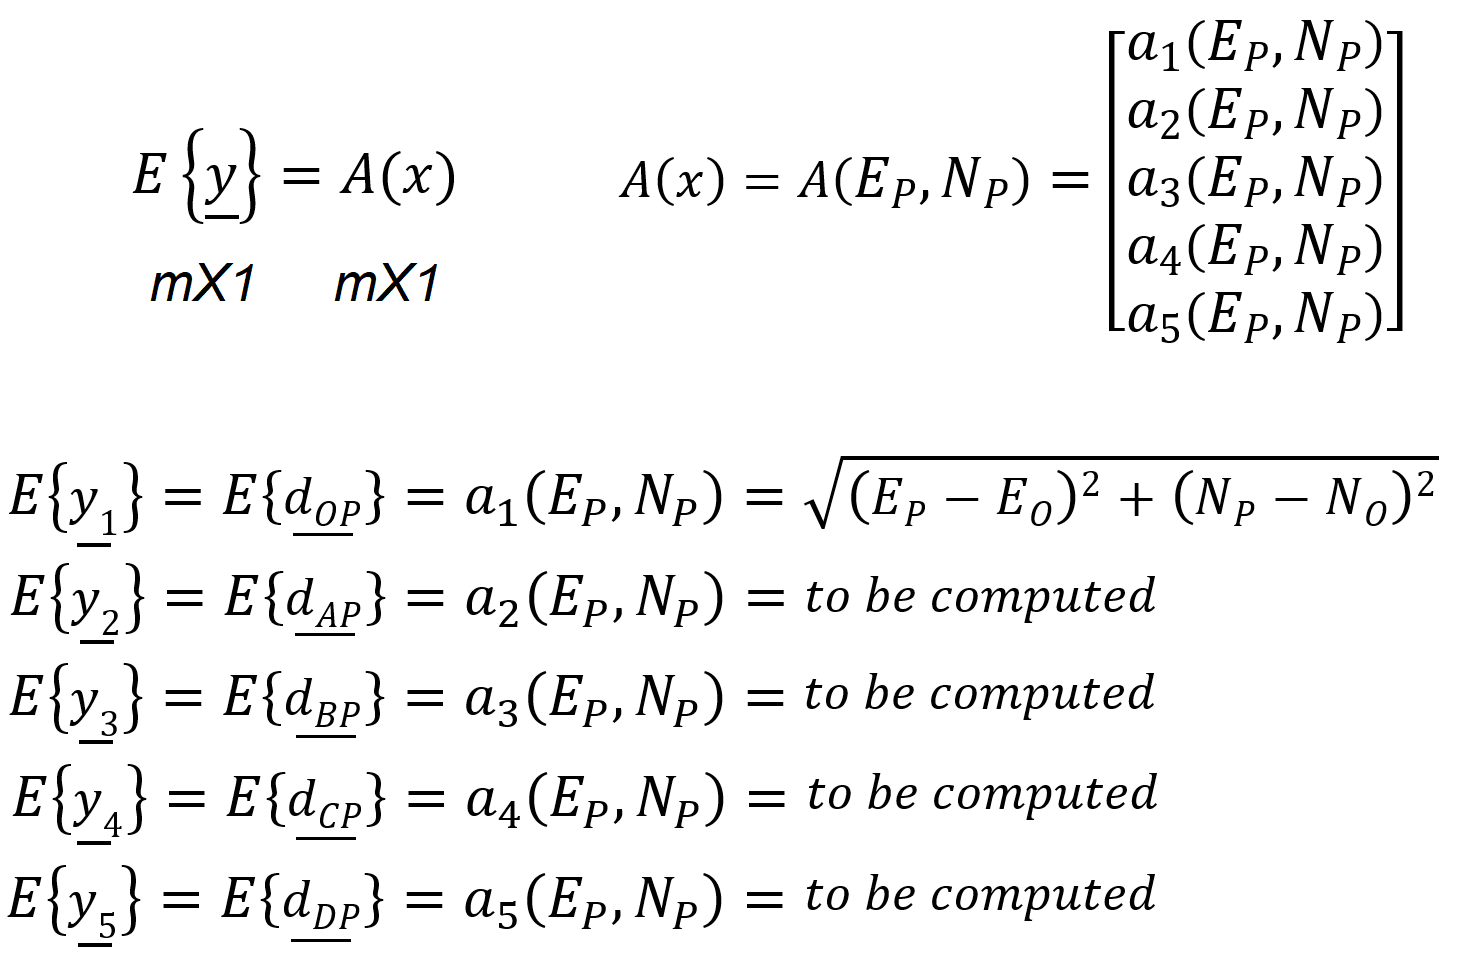

In [ ]:
# Define the function for the non-linear matrix A(x)
def non_linear_A_matrix(xi, m, EO, NO, EA, NA, EB, NB, EC, NC, ED, ND):

     # Depending on your implementation, you could be forced to change the following two lines
     EP = 0 # replace the 0 with xi[0,0]
     NP = 0 # replace the 0 with xi[1,0]

     A = np.zeros((m,1))
     A[0] = np.sqrt((EP-EO)**2+(NP-NO)**2)                           # a1(EP,NP)
     A[1] = 0 # replace the 0 with the correct expression            # a2(EP,NP)
     A[2] = 0 # replace the 0 with the correct expression            # a3(EP,NP)
     A[3] = 0 # replace the 0 with the correct expression            # a4(EP,NP)
     A[4] = 0 # replace the 0 with the correct expression            # a5(EP,NP)
     return A

Ai = non_linear_A_matrix(xi, m, EO, NO, EA, NA, EB, NB, EC, NC, ED, ND)
print('Ai\n',Ai)
print('Ai shape\n', Ai.shape)

**Definition of the Jacobian matrix**

Compute the derivatives according to the derivative rules ([link](https://www.mathsisfun.com/calculus/derivatives-rules.html)).

To help you, I provide the first derivative: at the exam this will not happen.

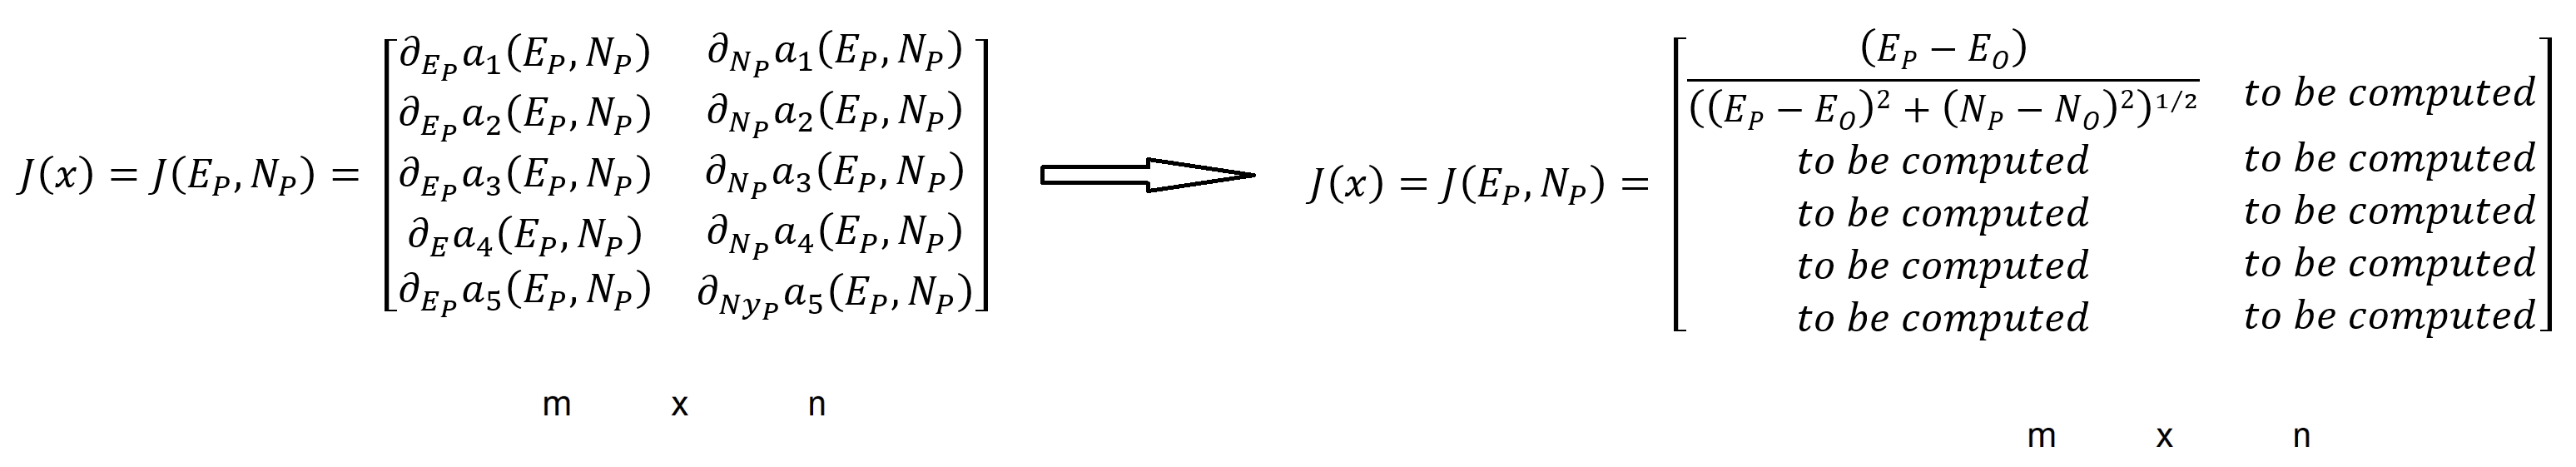

In [ ]:
# Define the function for the Jacobian matrix
def Jacobian (xi, m, n, EO, NO, EA, NA, EB, NB, EC, NC, ED, ND):
      # Depending on your implementation, you could be forced to change the following two lines
      EP = 0# replace the 0 with xi[0,0]
      NP = 0# replace the 0 with xi[1,0]

      J = np.zeros((m,n))
      J[0,0] = (EP-EO)/np.sqrt((EP-EO)**2+(NP-NO)**2)             #∂EP a1(EP,NP)
      J[0,1] = 0 # replace the 0 with the correct expression      #∂NP a1(EP,NP)

      J[1,0] =  0 # replace the 0 with the correct expression      #∂EP a2(EP,NP)
      J[1,1] =  0 # replace the 0 with the correct expression      #∂NP a2(EP,NP)

      J[2,0] =  0 # replace the 0 with the correct expression      #∂EP a3(EP,NP)
      J[2,1] =  0 # replace the 0 with the correct expression      #∂NP a3(EP,NP)

      J[3,0] =  0 # replace the 0 with the correct expression      #∂EP a4(EP,NP)
      J[3,1] =  0 # replace the 0 with the correct expression      #∂NP a4(EP,NP)

      J[4,0] =  0 # replace the 0 with the correct expression      #∂EP a5(EP,NP)
      J[4,1] =  0 # replace the 0 with the correct expression      #∂NP a5(EP,NP)

      return J

Ji = Jacobian(xi, m, n, EO, NO, EA, NA, EB, NB, EC, NC, ED, ND)

print('Ji\n',Ji)
print('Ji shape\n', Ji.shape)



**Gauss- Newton iterative scheme**

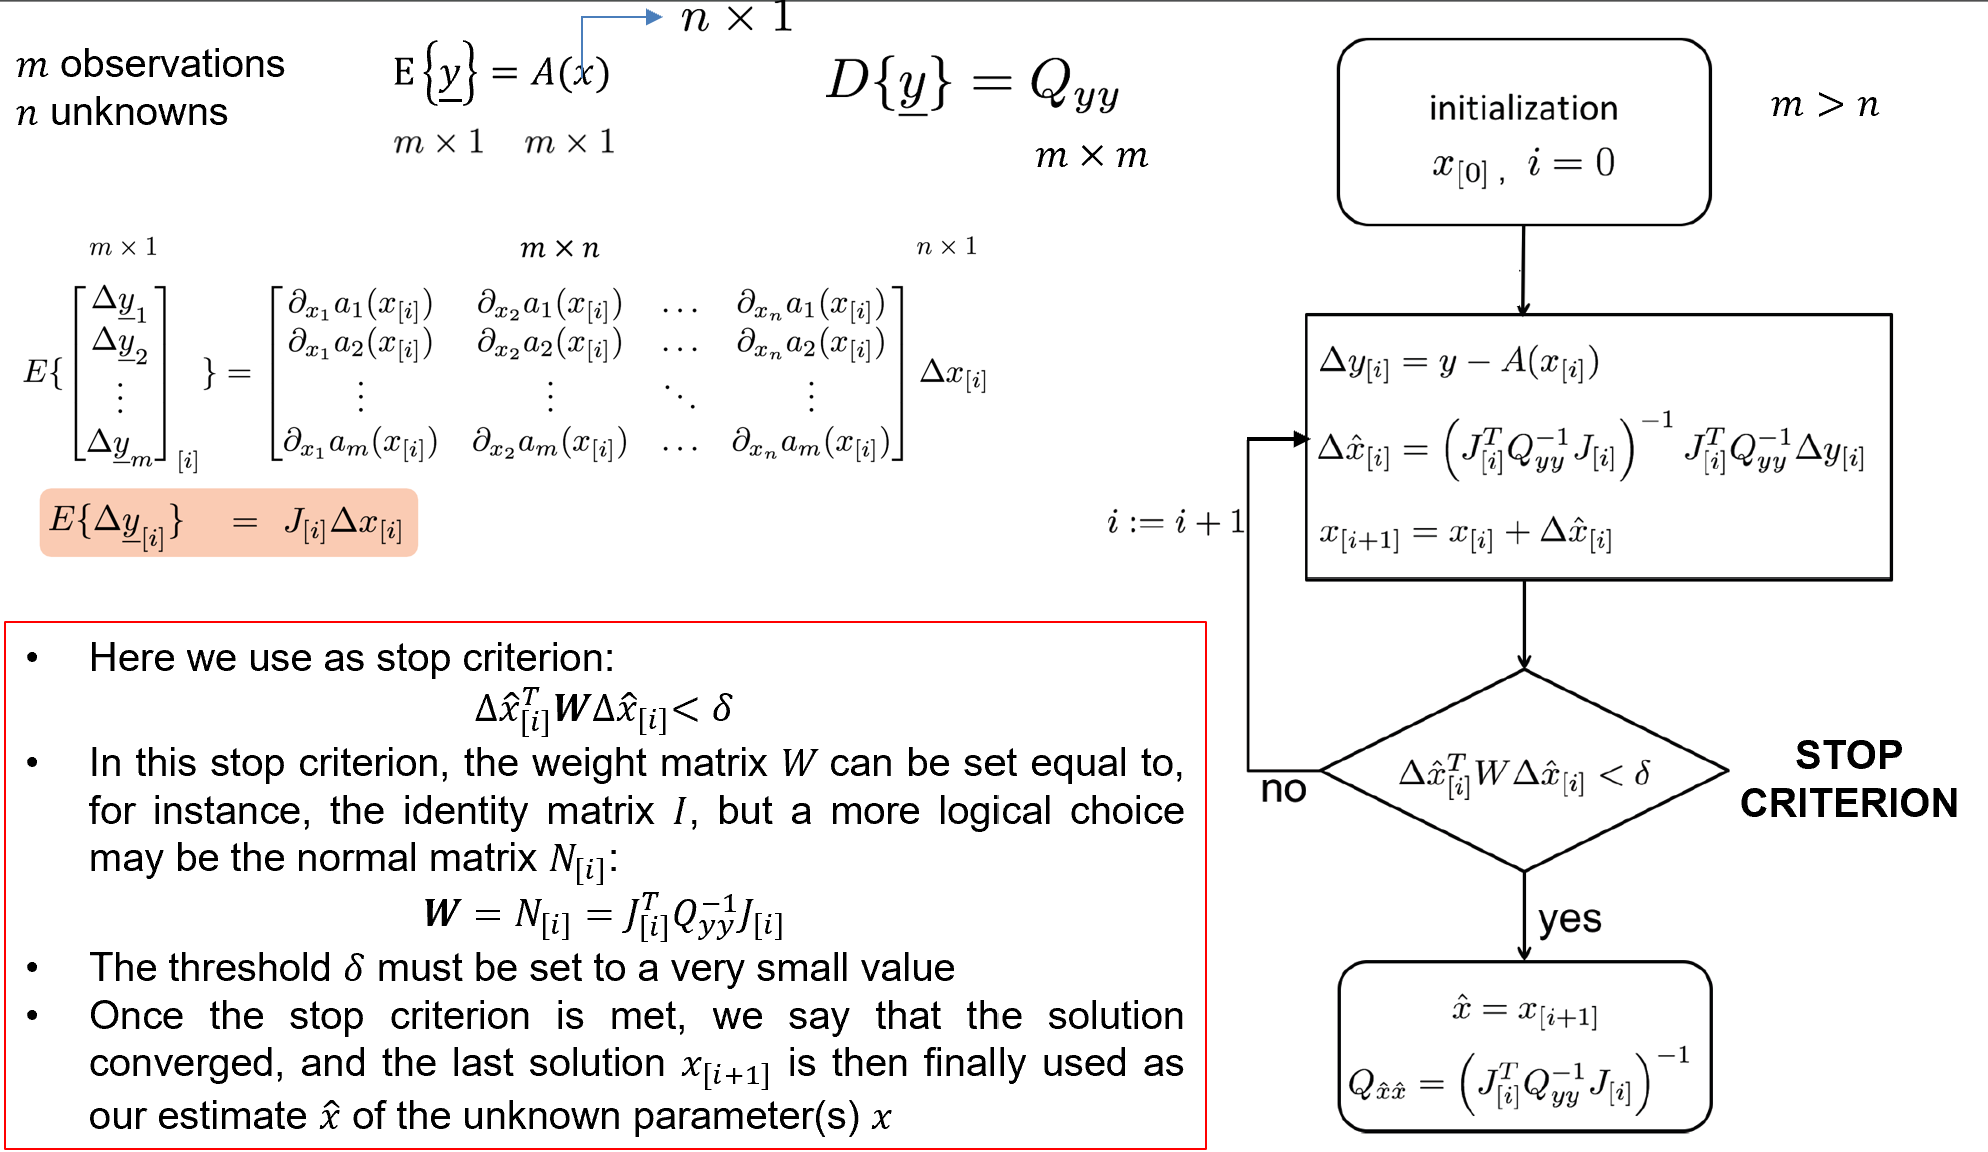

In [9]:
# The threshold 𝛿 must be set to a very small value
delta_stop = 10**(-6)

# Initial guess for the unknown coordinates of the point P
# Consider that you could be forced to reshape xi
xi = 0 # replace the 0 with the correct expression

# Set a high value for the error of the stop crtiterion,
# in order to be able to enter in the while loop (Gauss-Newton iteration scheme)
stop_metric = 10000

# Counter for the iterations
i = 0

# Gauss-Newton iteration scheme
# The second condition is to avoid to be stucked in the while loop forever if we do not achieve convergence
# After 100 iterations, we exit from the while loop
while (stop_metric > delta_stop) and (i<100):
      print('i:', i, '-> xi:\n', xi)

      # Define the non-linear A(x) matrix for the current iteration i and store it in a variable named Ai
      # Use the function you defined in the previous cell
      Ai  = 0 # replace the 0 with the correct expression
      #print('Ai\n',Ai)
      #print('Ai shape', Ai.shape)

      # Compute the delta y for the current iteration i and store it in a variable named dyi
      dyi = 0 # replace the 0 with the correct expression
      #print('dyi\n',dyi)
      #print('dyi shape', dyi.shape)

      # Define the Jacobian matrix for the current iteration i and store it in a variable named Ji
      Ji  =  0 # replace the 0 with the correct expression
      #print('Ji\n',Ji)
      #print('Ji shape', Ji.shape)

      # Compute the rank of the  Jacobian  matrix  at the current itertion i and store it in a variable named rankJi
      rankJi = 0 # replace the 0 with the correct expression
      #print('Rank of Ji\n', rankJi)

      # Compute the normal matrix for the current iteration i and store it in a variable named Ni
      Ni = 0 # replace the 0 with the correct expression
      #print('Ni\n',Ni)
      #print('Ni shape', Ni.shape)

      # Compute the inverse of the normal matrix for the current iteration i and store it in a variable named Ni_inv
      Ni_inv = 0 # replace the 0 with the correct expression
      #print('Ni_inv\n',Ni_inv)
      #print('Ni_inv shape', Ni_inv.shape)

      # Compute the correction(s) to the guess value(s) (delta x) for the current iteration i and store it in a variable named dxi
      dxi = 0 # replace the 0 with the correct expression

      # Update the value(s) of xi in order to be used as initial guess for the next iteration
      xi = 0 # replace the 0 with the correct expression

      # Define the weight matrix for the stop criterion
      W = 0 # replace the 0 with the correct expression

      # Update stop criterion: squared N-weighted norm of the parameter update
      stop_metric = 10000 # replace the 10000 with the correct expression
      i = i+1

print('xi (final solution) after ',i ,'iterations:\n', xi)

i: 0 -> xi:
 0
i: 1 -> xi:
 0
i: 2 -> xi:
 0
i: 3 -> xi:
 0
i: 4 -> xi:
 0
i: 5 -> xi:
 0
i: 6 -> xi:
 0
i: 7 -> xi:
 0
i: 8 -> xi:
 0
i: 9 -> xi:
 0
i: 10 -> xi:
 0
i: 11 -> xi:
 0
i: 12 -> xi:
 0
i: 13 -> xi:
 0
i: 14 -> xi:
 0
i: 15 -> xi:
 0
i: 16 -> xi:
 0
i: 17 -> xi:
 0
i: 18 -> xi:
 0
i: 19 -> xi:
 0
i: 20 -> xi:
 0
i: 21 -> xi:
 0
i: 22 -> xi:
 0
i: 23 -> xi:
 0
i: 24 -> xi:
 0
i: 25 -> xi:
 0
i: 26 -> xi:
 0
i: 27 -> xi:
 0
i: 28 -> xi:
 0
i: 29 -> xi:
 0
i: 30 -> xi:
 0
i: 31 -> xi:
 0
i: 32 -> xi:
 0
i: 33 -> xi:
 0
i: 34 -> xi:
 0
i: 35 -> xi:
 0
i: 36 -> xi:
 0
i: 37 -> xi:
 0
i: 38 -> xi:
 0
i: 39 -> xi:
 0
i: 40 -> xi:
 0
i: 41 -> xi:
 0
i: 42 -> xi:
 0
i: 43 -> xi:
 0
i: 44 -> xi:
 0
i: 45 -> xi:
 0
i: 46 -> xi:
 0
i: 47 -> xi:
 0
i: 48 -> xi:
 0
i: 49 -> xi:
 0
i: 50 -> xi:
 0
i: 51 -> xi:
 0
i: 52 -> xi:
 0
i: 53 -> xi:
 0
i: 54 -> xi:
 0
i: 55 -> xi:
 0
i: 56 -> xi:
 0
i: 57 -> xi:
 0
i: 58 -> xi:
 0
i: 59 -> xi:
 0
i: 60 -> xi:
 0
i: 61 -> xi:
 0
i: 62 -> xi:
 0
i:

**Overall Model Test - Non Linear case**

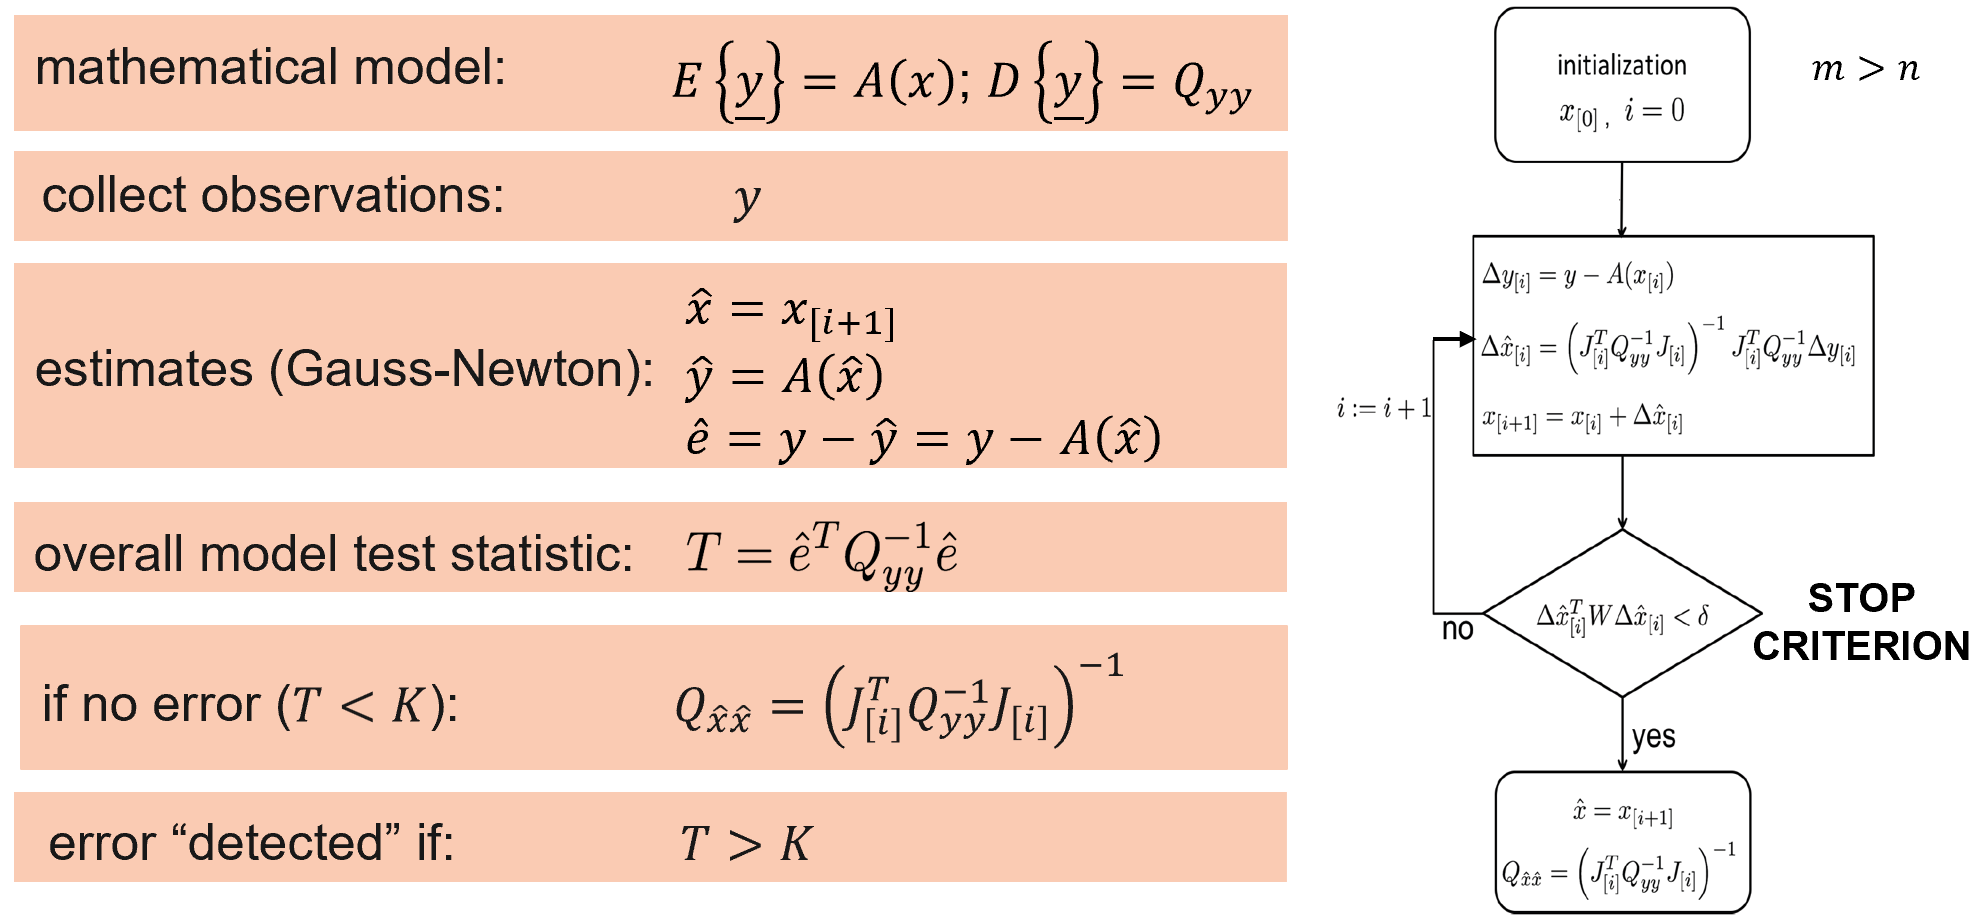

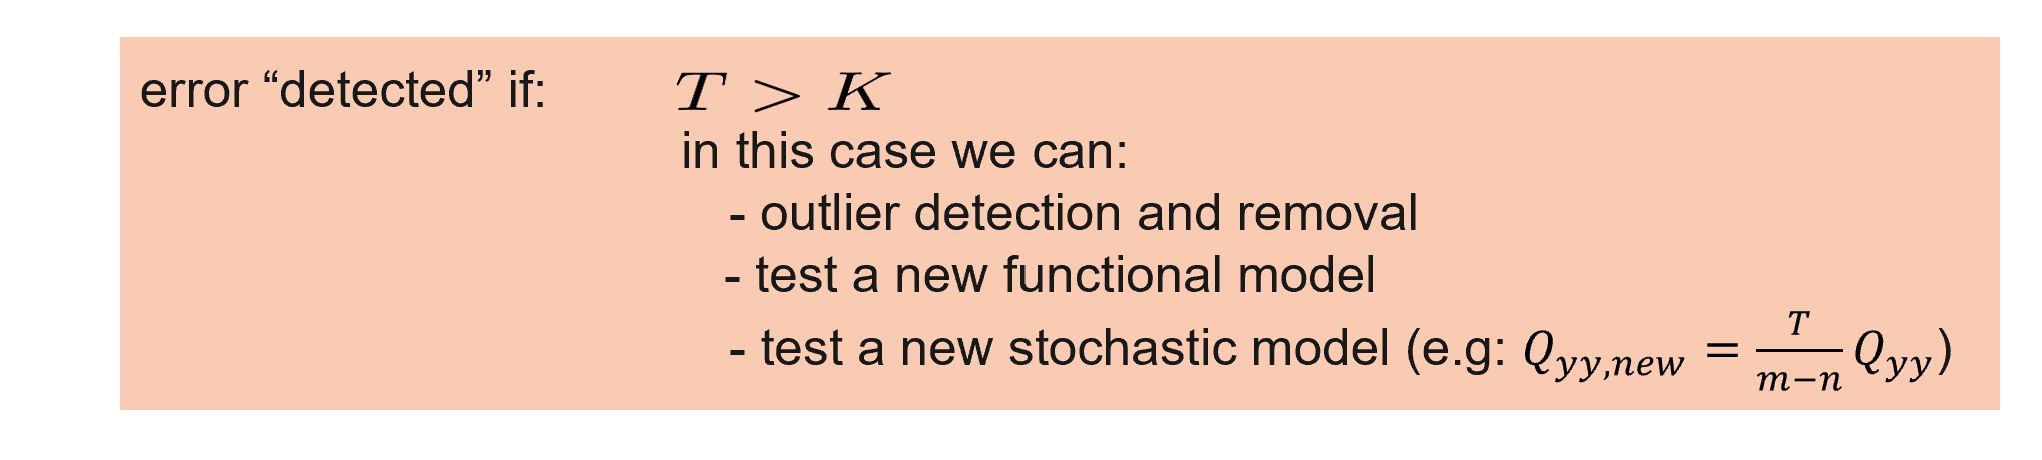

In [ ]:
xhat = 0 # replace the 0 with the correct expression
yhat = 0 # replace the 0 with the correct expression
ehat = 0 # replace the 0 with the correct expression
print('xhat\n', xhat)
#print('xhat shape\n', xhat.shape)
print('yhat\n', yhat)
#print('yhat shape\n', yhat.shape)
print('ehat\n', ehat)
#print('ehat shape\n', ehat.shape)

# Compute the covariance matrices of xhat, and store it in the variables named Qxhat
Qxhat = 0 # replace the 0 with the correct expression
print('Qxhat\n', Qxhat)
#print('Qxhat shape\n', Qxhat.shape)

# Compute the scaling factor for confidence interval
# (for example for 95% interval, the scaling factor should be 1.96)
conf_level= 0   # replace the 0 with the correct expression
cint_scale=norm.ppf(1-(1-conf_level)/2)

low_bound_EP = 0   # replace the 0 with the correct expression
up_bound_EP  = 0   # replace the 0 with the correct expression
low_bound_NP = 0   # replace the 0 with the correct expression
up_bound_NP  = 0   # replace the 0 with the correct expression
print("Scale factor for the confidence interval at ",  conf_level*100, "% probability: ", format(cint_scale,'0.2f'))
print('Conf. interval for EP at ' ,conf_level*100, "% probability:")
print('[',low_bound_EP,',',up_bound_EP,']')
print('Conf. interval for NP at ' ,conf_level*100, "% probability:")
print('[',low_bound_NP ,',',up_bound_NP,']')



# Compute the weighted sum of the squared residuals which will serve as the OMT test statistic T
# and store it in a variable named Tq
Tq = 0 # replace the 0 with the correct expression
#print('Tq',Tq.shape)
# Compute K using the chi square distribution for the desired alpha (significance level)
alpha = 0 # replace the 0 with the correct expression
degrees_of_freedom = 0 # replace the 0 with the correct expression
print("Degrees of freedom (redundance): ", degrees_of_freedom)
K = chi2.ppf(1-alpha, df=degrees_of_freedom)

print("K for the significance level of ",  alpha*100, "% and ", format(degrees_of_freedom,'0.0f'), 'degrees of freedom:', format(K,'0.3f'))


#print("T:", format(Tq[0,0],'0.3f'), "K:", format(K,'0.3f'))
if Tq<K:
  print("Test passed (T<K): model accepted")
else:
  print("Test not passed (T>K): model rejected")

# Identify the index for which you have the maxium residual







# Planimetric plot
plt.figure()
plt.plot(A[0],A[1], 'r^',label='A', markeredgecolor='k')
plt.plot(B[0],B[1], 'b^',label='B', markeredgecolor='k')
plt.plot(C[0],C[1], 'g^',label='C', markeredgecolor='k')
plt.plot(D[0],D[1], 'w^',label='C', markeredgecolor='k')
plt.plot(xhat[0,0],xhat[1,0], 'mo',label='P', markeredgecolor='k')
plt.plot(O[0],O[1], 'y^',label='O', markeredgecolor='k')
plt.text(A[0],A[1],'A')
plt.text(B[0],B[1],'B')
plt.text(C[0],C[1],'C')
plt.text(D[0],D[1],'D')
plt.text(O[0],O[1],'O')
plt.text(xhat[0,0],xhat[1,0],'P')
plt.xlabel('E (m)')
plt.ylabel('N (m)')
ax.axis('equal')
plt.grid()
plt.grid(which='minor')



# Plot the results
indexes = np.arange(0, m, 1, dtype=int)
# Plot the residuals
# Hint: on the x-axis, use the indexes of the observations


# Plot Qxhat
# Hint: use plt.imshow
# https://scipython.com/book/chapter-7-matplotlib/examples/visualizing-a-matrix-with-imshow/


plt.show()